# 부산광역시 야간조명(NTL)–야간 지표면온도(LST) 분석 (v3)
- 자료: VIIRS 월별 야간조명, MODIS Aqua 야간 LST(MYD11A1.061), MODIS NDVI(MOD13A2.061), SRTM 고도, ESA WorldCover(토지피복·육지/수면)
- 부산 경계: geoBoundaries ADM2(구·군) 16개를 합쳐서 사용
- 분석 단위: MODIS 약 1 km 격자, **같은 연월끼리** 비교
- 세부목적 1: **토지이용 유형별 NTL–LST 공간적 연관성 비교**
- 세부목적 2: 환경변수 보정 후 추가 설명력(ΔR²)
- 세부목적 3: 계절별 차이 + 유효 관측 수 기준 민감도

**세부목적 1의 토지이용 분류**
- ESA WorldCover 10 m 토지피복을 1 km 격자 내 최빈값(majority class)으로 집계
- 산림, 관목·초지, 농경지, 시가화지역, 나지·암석, 습지·맹그로브, 수면·설빙·기타로 구분
- WorldCover의 시가화지역은 주거·상업을 별도로 구분하지 않으므로, 본 분석에서 주거지역과 상업지역을 개별 비교하지 않음

**사용법**: 위에서부터 순서대로 실행. 1번 셀의 `GEE_PROJECT`만 바꾸면 됩니다.
4번(경계), 6번(시험 추출) 셀은 값이 이상하면 일부러 멈추도록 만들어 두었습니다.


In [2]:
# 1. 설정
import os, re, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import statsmodels.api as sm
from scipy import stats
import ee

GEE_PROJECT    = 'earth-engine-student-2026'   # <- 본인 Google Cloud 프로젝트 ID로 변경
START_YEAR     = 2022                    # 분석 기간 (VIIRS 월별 자료가 있는 구간 안에서 선택)
END_YEAR       = 2025
QA_STRICT      = False                   # False: LST 품질 'good + 보통'까지 사용 (True면 거의 다 버려짐)
MIN_LAND_FRAC  = 0.8                     # 1 km 격자 중 육지 비율이 이 값 이상인 격자만 사용
THRESHOLDS     = [1, 3, 5, 7, 10]        # 최소 유효 관측 수(한 달 중 LST가 유효한 밤의 수) 후보
BASE_MIN_VALID = 3                       # 세부목적 1~2의 기본 기준
FORCE_REEXTRACT = False                  # True면 저장된 CSV를 무시하고 Earth Engine에서 다시 추출

pd.set_option('display.float_format', '{:.3f}'.format)
pd.set_option('display.width', 200)

# 한글 폰트 (Colab에서 그래프 한글 깨짐 방지)
try:
    subprocess.run(['apt-get', '-qq', 'update'], check=True, capture_output=True)
    subprocess.run(['apt-get', '-qq', 'install', '-y', 'fonts-nanum'], check=True, capture_output=True)
    for p in fm.findSystemFonts(fontpaths=['/usr/share/fonts/truetype/nanum']):
        fm.fontManager.addfont(p)
    plt.rcParams['font.family'] = 'NanumGothic'
except Exception as e:
    print('한글 폰트 설치 실패(그래프 한글이 깨질 수 있음):', e)
plt.rcParams['axes.unicode_minus'] = False

# 결과 저장 위치: 드라이브 연결에 성공하면 드라이브, 아니면 Colab 임시 폴더
try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = '/content/drive/MyDrive/busan_ntl_lst'
except Exception as e:
    print('드라이브 연결 실패, 임시 폴더를 사용합니다:', e)
    BASE_DIR = '/content/busan_ntl_lst'
os.makedirs(BASE_DIR, exist_ok=True)
print('저장 폴더:', BASE_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
저장 폴더: /content/drive/MyDrive/busan_ntl_lst


In [3]:
# 2. Earth Engine 인증/초기화
ee.Authenticate()
ee.Initialize(project=GEE_PROJECT)
print('Earth Engine 연결 성공:', ee.Number(1).getInfo())

Earth Engine 연결 성공: 1


In [4]:
# 3. 부산 16개 구·군 경계 만들기 (geoBoundaries ADM2)
# 부산 전체 한 덩어리(ADM1)를 바로 쓰면 일부만 잡히는 문제가 있었기 때문에,
# 구·군(ADM2) 16개를 찾아서 합치는 방식으로 바꿨다. (교수님 코드도 같은 자료를 사용)
BOX = [128.70, 34.80, 129.40, 35.45]    # 부산을 넉넉히 덮는 사각형 [경도min, 위도min, 경도max, 위도max]
NAME_DICT = {
    'gangseo': '강서구', 'geumjeong': '금정구', 'gijang': '기장군', 'nam': '남구', 'dong': '동구',
    'dongnae': '동래구', 'busanjin': '부산진구', 'pusanjin': '부산진구', 'buk': '북구', 'sasang': '사상구',
    'saha': '사하구', 'seo': '서구', 'suyeong': '수영구', 'yeonje': '연제구', 'yeongdo': '영도구',
    'jung': '중구', 'haeundae': '해운대구'}
EXPECTED = set(NAME_DICT.values())

def korean_name(name):
    # 대괄호와 그 안의 내용(예: [North Distrikt])을 먼저 지웁니다.
    clean_name = re.sub(r'\[.*?\]', '', str(name))
    key = re.sub(r'[\s_\-]+', '', clean_name.strip().lower())
    key = re.sub(r'(district|county)$', '', key)
    key = re.sub(r'(gun|gu)$', '', key)
    return NAME_DICT.get(key, str(name))

adm2 = (ee.FeatureCollection('WM/geoLab/geoBoundaries/600/ADM2')
        .filter(ee.Filter.eq('shapeGroup', 'KOR'))
        .filterBounds(ee.Geometry.Rectangle(BOX)))

def add_info(f):
    f = ee.Feature(f)
    g = f.geometry()
    c = g.centroid(100).coordinates()
    return f.set({'cx': c.get(0), 'cy': c.get(1), 'area_km2': g.area(100).divide(1e6)})

info = adm2.map(add_info).select(['shapeName', 'shapeID', 'cx', 'cy', 'area_km2'], None, False)
cand = pd.DataFrame([f['properties'] for f in info.getInfo()['features']])
cand['district'] = cand['shapeName'].map(korean_name)
inside = cand['cx'].between(BOX[0], BOX[2]) & cand['cy'].between(BOX[1], BOX[3])
sel = cand[inside & cand['district'].isin(EXPECTED)].copy()

print('사각형 안의 시·군·구 후보:')
print(cand.sort_values('shapeName')[['shapeName', 'district', 'cx', 'cy', 'area_km2']].to_string(index=False))
assert len(sel) == 16 and sel['district'].nunique() == 16, (
    f'부산 구·군이 {len(sel)}개만 잡혔습니다(16개여야 함). 위 후보 표에서 빠진 구·군 이름을 확인하세요.')

districts = adm2.filter(ee.Filter.inList('shapeID', sel['shapeID'].tolist()))
busan = districts.geometry(100)

area_km2 = busan.area(100).getInfo() / 1e6
b = busan.bounds(100).coordinates().getInfo()[0]
lon_rng = (min(p[0] for p in b), max(p[0] for p in b))
lat_rng = (min(p[1] for p in b), max(p[1] for p in b))
print(f'\n부산 경계 면적: {area_km2:.0f} km² | 경도 {lon_rng[0]:.2f}~{lon_rng[1]:.2f} | 위도 {lat_rng[0]:.2f}~{lat_rng[1]:.2f}')
print('구·군별 면적(km²):')
print(sel.sort_values('area_km2', ascending=False)[['district', 'area_km2']].to_string(index=False))
assert 650 < area_km2 < 950, (
    f'면적이 {area_km2:.0f} km²입니다. 부산은 약 770 km²여야 합니다. 위 구·군별 면적에서 이상한 구·군을 확인하세요.')
assert lon_rng[0] < 128.85 and lon_rng[1] > 129.25, '강서구(서쪽) 또는 기장군(동쪽)이 빠진 것 같습니다.'

사각형 안의 시·군·구 후보:
                 shapeName    district      cx     cy  area_km2
   Buk-gu [North Distrikt]          북구 129.024 35.229    40.494
               Busanjin-gu        부산진구 129.042 35.154    21.666
               Changwon-si Changwon-si 128.596 35.209   708.130
   Dong-gu [East District]          동구 129.047 35.128     5.132
                Dongnae-gu         동래구 129.074 35.197    26.736
                Gangseo-gu         강서구 128.907 35.157   133.140
                  Geoje-si    Geoje-si 128.628 34.872   349.043
              Geumjeong-gu         금정구 129.095 35.253    63.219
                Gijang-gun         기장군 129.199 35.292   203.686
                 Gimhae-si   Gimhae-si 128.846 35.267   474.021
               Haeundae-gu        해운대구 129.154 35.190    42.660
Jung-gu [Central District]          중구 129.034 35.112     3.342
                Miryang-si  Miryang-si 128.790 35.494   784.921
   Nam-gu [South District]          남구 129.093 35.128    19.407
                   Saha

In [19]:
# 4. 격자 기준과 고정 변수: 육지 비율, 고도, 해안(수면)까지 거리
# 기준 격자 = MODIS 1 km 격자. 다른 자료는 이 격자로 평균 집계한다.
PROJ = ee.ImageCollection('MODIS/061/MYD11A1').first().select('LST_Night_1km').projection()

def to_grid(img, src_proj=None):
    """해상도가 다른 영상을 MODIS 1 km 격자로 평균 집계"""
    if src_proj is not None:
        img = img.setDefaultProjection(src_proj)
    return img.reduceResolution(reducer=ee.Reducer.mean(), maxPixels=65536).reproject(PROJ)

worldcover = ee.ImageCollection('ESA/WorldCover/v200').first().select('Map')
water = worldcover.unmask(80).eq(80)                 # 80 = 영구 수면. 자료가 없는 바다도 수면으로 본다.
land_frac = to_grid(water.Not()).rename('land_frac') # 1 km 격자 안의 육지 비율
elev = to_grid(ee.Image('USGS/SRTMGL1_003').select('elevation')).rename('elev')

# 수면까지 거리: 250 m 격자에서 계산한 뒤 1 km로 집계
# 주의: 큰 하천(낙동강 등)도 수면이라 '가장 가까운 물'까지의 거리에 가깝다.
proj250 = ee.Projection('EPSG:4326').atScale(250)
water_frac250 = water.reduceResolution(ee.Reducer.mean(), maxPixels=4096).reproject(proj250)
sea250 = (water_frac250.gt(0.5)
          .focalMin(radius=3, kernelType='circle', units='pixels')
          .focalMax(radius=3, kernelType='circle', units='pixels'))
dist_m = sea250.distance(ee.Kernel.euclidean(30000, 'meters'))
coast_km = to_grid(dist_m.divide(1000)).rename('coast_km')

# 부산형 3개 토지이용 유형 재분류
# 1 = 시가화지역
# 2 = 농경지
# 3 = 녹지·자연지역
# 7 = 수면(분석 제외)

wc_classes = [10, 20, 30, 40, 50, 60, 70, 80, 90, 95, 100]
wc_groups  = [ 3,  3,  3,  2,  1,  3,  3,  7,  3,  3,   3]

landuse_10m = worldcover.remap(
    wc_classes, wc_groups
).rename('landuse')

landuse_1km = (
    landuse_10m
    .reduceResolution(
        reducer=ee.Reducer.mode(),
        maxPixels=65536
    )
    .reproject(PROJ)
    .rename('landuse')
)

In [20]:
# 5. 월별 영상 만들기 + 부산 1 km 격자 값 추출
def mask_lst(img):
    qc = img.select('QC_Night')
    mandatory = qc.bitwiseAnd(3)                       # bit0-1: 0=좋음, 1=보통, 2·3=LST 미생성(구름 등)
    good = mandatory.eq(0) if QA_STRICT else mandatory.lte(1)
    lst = img.select('LST_Night_1km').multiply(0.02).subtract(273.15)   # K -> 섭씨
    return lst.updateMask(good).rename('LST')

def mask_ndvi(img):
    ok = img.select('SummaryQA').lte(1)                # 0 good, 1 marginal
    return img.select('NDVI').multiply(0.0001).updateMask(ok).rename('NDVI')

viirs_all = ee.ImageCollection('NOAA/VIIRS/DNB/MONTHLY_V1/VCMSLCFG').select('avg_rad')
VIIRS_PROJ = viirs_all.first().projection()

def month_stack(year, month):
    start = ee.Date.fromYMD(year, month, 1)
    end = start.advance(1, 'month')
    lst_c = ee.ImageCollection('MODIS/061/MYD11A1').filterDate(start, end).map(mask_lst)
    lst = lst_c.mean().rename('LST')                   # 월평균 야간 LST
    n_valid = lst_c.count().rename('n_valid')          # 월 유효 관측 수
    ntl = to_grid(viirs_all.filterDate(start, end).mean(), VIIRS_PROJ).rename('ntl')
    ndvi = (ee.ImageCollection('MODIS/061/MOD13A2').filterDate(start, end)
            .map(mask_ndvi).mean().rename('NDVI'))     # MYD11A1과 같은 1 km 격자
    return ee.Image.cat([lst, n_valid, ntl, ndvi, elev, coast_km, land_frac, landuse_1km])

def sample_month(year, month, retries=3):
    img = month_stack(year, month)
    # dropNulls=False: 결측이 있어도 격자를 남겨두고 파이썬에서 거른다 (어느 변수가 비는지 보이게)
    fc = img.sample(region=busan, projection=PROJ, geometries=True, dropNulls=False)
    for k in range(retries):
        try:
            info = fc.getInfo()
            break
        except Exception as e:
            print('  재시도', k + 1, e)
    else:
        return []
    rows = []
    for f in info['features']:
        p = dict(f['properties'])
        lon, lat = f['geometry']['coordinates']
        p.update(lon=lon, lat=lat, year=year, month=month)
        rows.append(p)
    return rows

In [21]:
# 6. 시험 추출 (한 달만): 이 결과가 정상이어야 전체 추출로 넘어간다
VARS_CHECK = ['LST', 'n_valid', 'ntl', 'NDVI', 'elev', 'coast_km', 'land_frac', 'landuse']
t = pd.DataFrame(sample_month(2021, 7))
print('2021-07 격자 수:', len(t), '(부산 전체면 대략 800~1000개)')
print('변수별 값이 있는 격자 수:')
print(t[VARS_CHECK].notna().sum())
print('\n수치 요약:')
print(t[VARS_CHECK].describe().T[['count', 'min', 'mean', 'max']])
assert len(t) > 600, '격자가 너무 적습니다. 3번 셀의 경계 출력(면적, 범위)을 다시 확인하세요.'
for v in ['ntl', 'elev', 'coast_km', 'land_frac']:
    assert t[v].notna().mean() > 0.9, f'{v} 값이 대부분 비어 있습니다. 4번 셀을 점검하세요.'
if t['LST'].notna().mean() < 0.3:
    print('경고: LST가 있는 격자가 30% 미만입니다. QA_STRICT=False인지, 영상 수는 충분한지 확인하세요.')

2021-07 격자 수: 768 (부산 전체면 대략 800~1000개)
변수별 값이 있는 격자 수:
LST          758
n_valid      758
ntl          768
NDVI         731
elev         768
coast_km     768
land_frac    768
landuse      768
dtype: int64

수치 요약:
            count    min    mean     max
LST       758.000 15.163  21.490  24.863
n_valid   758.000  1.000   4.612  10.000
ntl       768.000  1.594  19.216 129.644
NDVI      731.000  0.172   0.674   0.946
elev      768.000  0.415 115.226 626.277
coast_km  768.000  0.217   6.942  17.112
land_frac 768.000  0.389   0.959   1.000
landuse   768.000  1.000   2.486   7.000


In [22]:
pts = {'해운대 해수욕장': (129.160, 35.159), '서면': (129.059, 35.158),
       '동래': (129.085, 35.205), '금정산 고당봉': (129.055, 35.283)}
for name, (lo, la) in pts.items():
    i = ((t['lon'] - lo)**2 + (t['lat'] - la)**2).idxmin()
    print(f"{name}: 해안거리 {t.loc[i, 'coast_km']:.2f} km")
print('전체 최대 해안거리:', round(t['coast_km'].max(), 1), 'km')

해운대 해수욕장: 해안거리 0.77 km
서면: 해안거리 3.53 km
동래: 해안거리 6.99 km
금정산 고당봉: 해안거리 16.10 km
전체 최대 해안거리: 17.1 km


In [23]:
# 7. 전체 기간 추출 (몇 분 걸림). 저장 파일이 있고 정상이면 다시 추출하지 않는다.
CSV_PATH = f'{BASE_DIR}/busan_ntl_lst_{START_YEAR}_{END_YEAR}_landuse_v3_qa{int(QA_STRICT)}.csv'

def cache_ok(d):
    return len(d) > 0 and 'landuse' in d.columns and d.groupby(['year', 'month']).size().median() >= 600

raw = None
if os.path.exists(CSV_PATH) and not FORCE_REEXTRACT:
    cached = pd.read_csv(CSV_PATH)
    if cache_ok(cached):
        raw = cached
        print('저장된 파일을 불러왔습니다:', CSV_PATH, raw.shape)
    else:
        print('저장된 파일이 비정상(격자 수 부족)이라 다시 추출합니다.')

if raw is None:
    all_rows = []
    for y in range(START_YEAR, END_YEAR + 1):
        for m in range(1, 13):
            rows = sample_month(y, m)
            all_rows += rows
            n_lst = sum(1 for r in rows if r.get('LST') is not None)
            print(f'{y}-{m:02d}: 격자 {len(rows)}개 (LST 있음 {n_lst})')
    raw = pd.DataFrame(all_rows)
    assert cache_ok(raw), '추출 결과가 비정상입니다(월별 격자 수 부족). 6번 셀 시험 추출부터 다시 확인하세요.'
    raw.to_csv(CSV_PATH, index=False)
    print('저장 완료:', CSV_PATH, raw.shape)

저장된 파일을 불러왔습니다: /content/drive/MyDrive/busan_ntl_lst/busan_ntl_lst_2022_2025_landuse_v3_qa0.csv (36864, 12)


원본 36864 → 육지 비율 필터 34032 → 결측 제거 32719 행
격자 수: 471 | 연월 수: 48
토지이용 유형별 격자 수:
landuse_type
시가화지역      429
녹지·자연지역     36
농경지          6
dtype: int64
             count    mean     std    min    25%     50%     75%     max
LST      22091.000   9.881   8.450 -7.235  1.422  10.387  17.697  25.470
n_valid  22091.000   8.576   4.651  1.000  5.000   8.000  12.000  27.000
ntl      22091.000  12.729  10.949  0.000  4.703   9.236  16.930 139.374
ln_ntl   22091.000   2.346   0.737  0.000  1.741   2.326   2.886   4.944
NDVI     22091.000   0.627   0.172  0.048  0.502   0.635   0.773   0.974
elev     22091.000 167.893 122.094  0.961 79.310 145.249 245.833 626.277
coast_km 22091.000   7.425   4.118  0.391  3.972   6.967  10.707  17.112
격자 수가 100 미만인 달(제외):
 Series([], dtype: int64)


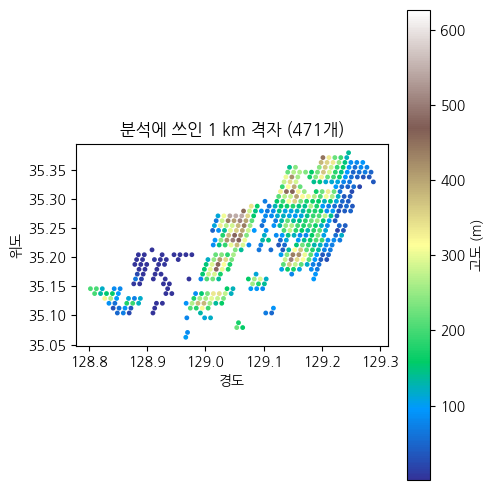

In [24]:
# 8. 전처리
df = raw.copy()
n0 = len(df)
df = df[df['land_frac'] >= MIN_LAND_FRAC]
n1 = len(df)
df = df.dropna(subset=['LST', 'ntl', 'NDVI', 'elev', 'coast_km', 'landuse']).copy()
n2 = len(df)
print(f'원본 {n0} → 육지 비율 필터 {n1} → 결측 제거 {n2} 행')
assert n2 > 0, '전처리 후 0행입니다. 위 단계별 행 수를 보고 어느 단계에서 사라졌는지 확인하세요.'

df['ym'] = df['year'].astype(int).astype(str) + '-' + df['month'].astype(int).astype(str).str.zfill(2)
df['pid'] = df['lon'].round(5).astype(str) + '_' + df['lat'].round(5).astype(str)
df['pid_code'] = pd.factorize(df['pid'])[0]            # 같은 격자의 반복 관측을 묶는 용도(군집 표준오차)
df['ln_ntl'] = np.log1p(df['ntl'].clip(lower=0))
# ESA WorldCover 최빈 토지피복 코드 -> 분석용 유형명
LANDUSE_LABELS = {
    1: '시가화지역',
    2: '농경지',
    3: '녹지·자연지역'
}
df['landuse_code'] = pd.to_numeric(df['landuse'], errors='coerce')
df = df[df['landuse_code'].isin(LANDUSE_LABELS)].copy()
df['landuse_type'] = df['landuse_code'].astype(int).map(LANDUSE_LABELS)
SEASON = {12: 'Winter', 1: 'Winter', 2: 'Winter', 3: 'Spring', 4: 'Spring', 5: 'Spring',
          6: 'Summer', 7: 'Summer', 8: 'Summer', 9: 'Autumn', 10: 'Autumn', 11: 'Autumn'}
df['season'] = df['month'].astype(int).map(SEASON)

print('격자 수:', df['pid'].nunique(), '| 연월 수:', df['ym'].nunique())
print('토지이용 유형별 격자 수:')
print(df.drop_duplicates('pid').groupby('landuse_type').size().sort_values(ascending=False))
print(df[['LST', 'n_valid', 'ntl', 'ln_ntl', 'NDVI', 'elev', 'coast_km']].describe().T)

# 표본이 너무 적은 달 제외 (구름이 많은 달)
cnt = df.groupby('ym').size()
print('격자 수가 100 미만인 달(제외):\n', cnt[cnt < 100])
df = df[df['ym'].isin(cnt[cnt >= 100].index)].copy()
assert len(df) > 0, '표본이 100격자 이상인 달이 없습니다.'

# 추출된 격자가 부산 전체를 덮는지 눈으로 확인
cells = df.drop_duplicates('pid')
plt.figure(figsize=(5, 5))
plt.scatter(cells['lon'], cells['lat'], s=6, c=cells['elev'], cmap='terrain')
plt.colorbar(label='고도 (m)')
plt.title(f'분석에 쓰인 1 km 격자 ({len(cells)}개)')
plt.xlabel('경도'); plt.ylabel('위도'); plt.gca().set_aspect('equal')
plt.tight_layout(); plt.show()

In [25]:
# 9. 분석 함수
# 핵심 아이디어: "같은 연월 안에서의 공간 차이"만 보기 위해 각 변수에서 연월 평균을 뺀다(demeaning).
# 이렇게 하면 연월 고정효과를 넣은 회귀와 같고, 계수는 '야간조명이 1 SD 높은 격자가 몇 °C 더 따뜻한가'를 뜻한다.
VARS = ['LST', 'ln_ntl', 'coast_km', 'elev', 'NDVI']
ZVARS = ['ln_ntl', 'coast_km', 'elev', 'NDVI']
# 표준화 기준(SD)은 전체 자료에서 한 번만 계산해 계절·기준 간 계수를 같은 단위로 비교
SD = {v: (df[v] - df.groupby('ym')[v].transform('mean')).std() for v in ZVARS}
ENV = ['coast_km_z', 'elev_z', 'NDVI_z']

def prep(d):
    d = d.copy()
    for v in VARS:
        d[v + '_d'] = d[v] - d.groupby('ym')[v].transform('mean')
    for v in ZVARS:
        d[v + '_z'] = d[v + '_d'] / SD[v]
    return d

def ols(d, xs):
    # 상수항 없음(이미 평균을 뺐으므로). 같은 격자의 반복 관측은 군집 표준오차로 처리
    return sm.OLS(d['LST_d'], d[xs]).fit(cov_type='cluster', cov_kwds={'groups': d['pid_code']})

def fit_set(d):
    d = prep(d)
    m0 = ols(d, ['ln_ntl_z'])                 # 세부목적 1: 단순 모형
    m1 = ols(d, ENV)                          # 환경변수만
    m2 = ols(d, ['ln_ntl_z'] + ENV)           # 환경변수 + 야간조명
    ci = m2.conf_int().loc['ln_ntl_z']
    return dict(n=len(d), n_pixel=d['pid_code'].nunique(), n_ym=d['ym'].nunique(),
                beta_simple=m0.params['ln_ntl_z'], r2_simple=m0.rsquared,
                beta_adj=m2.params['ln_ntl_z'], ci_lo=ci.iloc[0], ci_hi=ci.iloc[1],
                p_adj=m2.pvalues['ln_ntl_z'],
                r2_env=m1.rsquared, r2_full=m2.rsquared, delta_r2=m2.rsquared - m1.rsquared)

base = df[df['n_valid'] >= BASE_MIN_VALID].copy()
print('기본 분석 표본:', len(base), '행 (유효 관측 수 >=', BASE_MIN_VALID, ')')
assert len(base) > 300, (
    f'기본 표본이 {len(base)}행뿐입니다. BASE_MIN_VALID를 1~2로 낮추거나 QA_STRICT, 분석 기간을 확인하세요.')

기본 분석 표본: 20889 행 (유효 관측 수 >= 3 )


전체 격자 단순모형
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ln_ntl_z       0.4923      0.032     15.320      0.000       0.429       0.555
전체 격자 단순모형 R² = 0.153


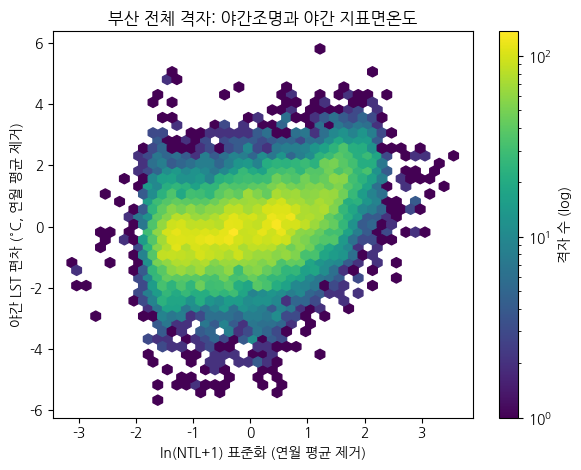

토지이용 유형별 월별 상관계수 요약
             pearson                           spearman                           beta_month                          
               count  mean median    min   max    count  mean median    min   max      count  mean median    min   max
landuse_type                                                                                                          
녹지·자연지역           39 0.209  0.281 -0.302 0.538       39 0.086  0.152 -0.368 0.408         39 0.615  0.684 -0.714 2.272
시가화지역             48 0.432  0.425 -0.070 0.783       48 0.415  0.428 -0.090 0.779         48 0.714  0.723 -0.133 1.695
토지이용 유형별 동일 연월 내 회귀 결과
landuse_type     n  n_pixel  n_ym   beta  ci_lo  ci_hi  p_value    r2
       시가화지역 19103      429    48  0.517  0.455  0.580    0.000 0.181
     녹지·자연지역  1524       36    48  0.217 -0.079  0.513    0.150 0.034
         농경지   262        6    48 -0.063 -0.317  0.191    0.625 0.005


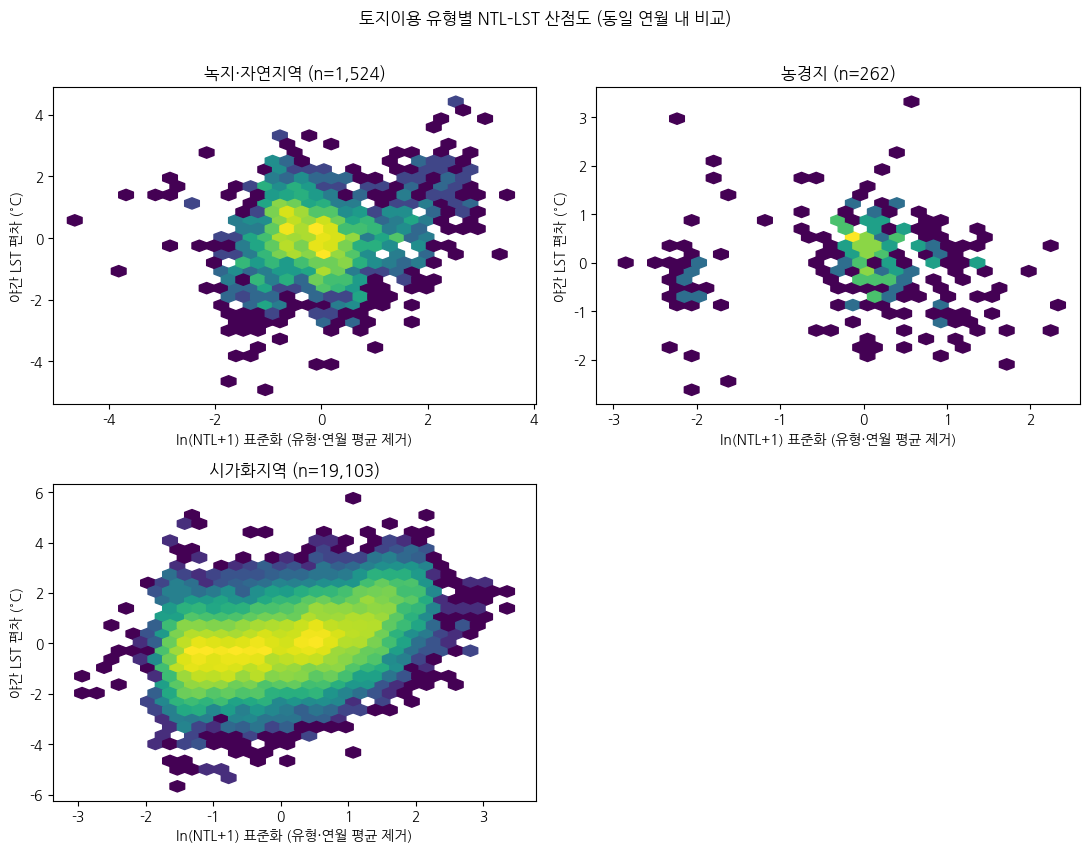

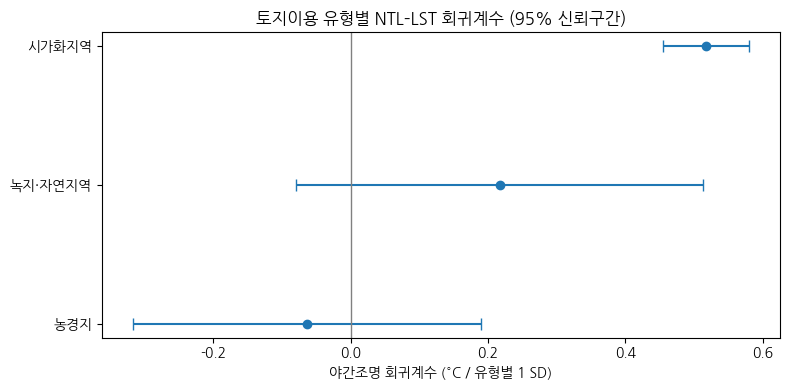

In [26]:
# 10. 세부목적 1: 토지이용 유형별 동일 연월 NTL–LST 공간적 연관성 비교
# ① 전체 격자 분포 확인
# ② 토지이용 유형별 산점도
# ③ 유형별로 연월 평균을 제거한 회귀계수(동일 연월 내 공간 비교) 추정

# 기존 전체 격자의 월별 상관계수 표도 유지 (후속 저장 셀에서 사용)
monthly_rows = []
for ym, g in base.groupby('ym'):
    if len(g) < 30:
        continue
    monthly_rows.append({
        'ym': ym,
        'n': len(g),
        'pearson': g['ln_ntl'].corr(g['LST']),
        'spearman': stats.spearmanr(g['ln_ntl'], g['LST'])[0]
    })
monthly = pd.DataFrame(monthly_rows).set_index('ym')

# 전체 격자: 월별 평균을 제거한 산점도
bd = prep(base)
m0 = ols(bd, ['ln_ntl_z'])
print('전체 격자 단순모형')
print(m0.summary().tables[1])
print('전체 격자 단순모형 R² =', round(m0.rsquared, 3))

plt.figure(figsize=(6, 4.8))
plt.hexbin(bd['ln_ntl_z'], bd['LST_d'], gridsize=40, cmap='viridis', mincnt=1, bins='log')
plt.colorbar(label='격자 수 (log)')
plt.xlabel('ln(NTL+1) 표준화 (연월 평균 제거)')
plt.ylabel('야간 LST 편차 (°C, 연월 평균 제거)')
plt.title('부산 전체 격자: 야간조명과 야간 지표면온도')
plt.tight_layout()
plt.show()

# 토지이용 유형별 동일 연월 내 상관계수 및 월별 회귀계수
# 유형-연월별 표본이 30개 미만이면 해당 월은 제외
monthly_landuse_rows = []
for (landuse_type, ym), g in base.groupby(['landuse_type', 'ym']):
    if len(g) < 30 or g['ln_ntl'].nunique() < 2:
        continue
    slope, intercept, r_value, p_value, std_err = stats.linregress(g['ln_ntl'], g['LST'])
    monthly_landuse_rows.append({
        'landuse_type': landuse_type,
        'ym': ym,
        'n': len(g),
        'pearson': g['ln_ntl'].corr(g['LST']),
        'spearman': stats.spearmanr(g['ln_ntl'], g['LST'])[0],
        'beta_month': slope,
        'p_month': p_value
    })

landuse_monthly = pd.DataFrame(monthly_landuse_rows)
if len(landuse_monthly):
    print('토지이용 유형별 월별 상관계수 요약')
    print(landuse_monthly.groupby('landuse_type')[['pearson', 'spearman', 'beta_month']].agg(
        ['count', 'mean', 'median', 'min', 'max']).round(3))
else:
    print('토지이용 유형별 월별 분석에 필요한 표본이 부족합니다.')

# 유형별 pooled 회귀: 각 토지이용 유형 안에서 연월 평균을 제거
# ln(NTL)은 유형별 동일 연월 편차의 표준편차로 표준화
landuse_reg_rows = []
landuse_scatter_data = {}
for landuse_type, g0 in base.groupby('landuse_type'):
    g = g0.copy()
    g['LST_d_type_ym'] = g['LST'] - g.groupby('ym')['LST'].transform('mean')
    g['ln_ntl_d_type_ym'] = g['ln_ntl'] - g.groupby('ym')['ln_ntl'].transform('mean')
    x_sd = g['ln_ntl_d_type_ym'].std()
    if len(g) < 100 or g['ym'].nunique() < 3 or not np.isfinite(x_sd) or x_sd == 0:
        print(landuse_type, ': pooled 회귀 표본 부족으로 제외')
        continue
    g['ln_ntl_z_type'] = g['ln_ntl_d_type_ym'] / x_sd
    model = sm.OLS(g['LST_d_type_ym'], g[['ln_ntl_z_type']]).fit(
        cov_type='cluster', cov_kwds={'groups': g['pid_code']})
    ci = model.conf_int().loc['ln_ntl_z_type']
    landuse_reg_rows.append({
        'landuse_type': landuse_type,
        'n': len(g),
        'n_pixel': g['pid_code'].nunique(),
        'n_ym': g['ym'].nunique(),
        'beta': model.params['ln_ntl_z_type'],
        'ci_lo': ci.iloc[0],
        'ci_hi': ci.iloc[1],
        'p_value': model.pvalues['ln_ntl_z_type'],
        'r2': model.rsquared
    })
    landuse_scatter_data[landuse_type] = g

landuse_results = pd.DataFrame(landuse_reg_rows)
if len(landuse_results):
    landuse_results = landuse_results.sort_values('beta', ascending=False).reset_index(drop=True)
    print('토지이용 유형별 동일 연월 내 회귀 결과')
    print(landuse_results.round(4).to_string(index=False))
else:
    print('토지이용 유형별 회귀 결과가 없습니다.')

# 유형별 산점도: 각 유형 안에서 연월 평균을 제거한 값 사용
types_to_plot = list(landuse_scatter_data.keys())
if types_to_plot:
    ncols = 2
    nrows = int(np.ceil(len(types_to_plot) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(11, 4.2 * nrows), squeeze=False)
    for ax, landuse_type in zip(axes.flat, types_to_plot):
        g = landuse_scatter_data[landuse_type]
        hb = ax.hexbin(g['ln_ntl_z_type'], g['LST_d_type_ym'],
                       gridsize=30, cmap='viridis', mincnt=1, bins='log')
        ax.set_title(f'{landuse_type} (n={len(g):,})')
        ax.set_xlabel('ln(NTL+1) 표준화 (유형·연월 평균 제거)')
        ax.set_ylabel('야간 LST 편차 (°C)')
    for ax in axes.flat[len(types_to_plot):]:
        ax.axis('off')
    fig.suptitle('토지이용 유형별 NTL–LST 산점도 (동일 연월 내 비교)', y=1.01)
    plt.tight_layout()
    plt.show()

# 유형별 회귀계수와 95% 신뢰구간 비교
if len(landuse_results):
    plot_df = landuse_results.sort_values('beta')
    y = np.arange(len(plot_df))
    xerr = np.vstack([plot_df['beta'] - plot_df['ci_lo'],
                      plot_df['ci_hi'] - plot_df['beta']])
    plt.figure(figsize=(8, max(4, 0.65 * len(plot_df))))
    plt.errorbar(plot_df['beta'], y, xerr=xerr, fmt='o', capsize=4)
    plt.axvline(0, color='gray', lw=1)
    plt.yticks(y, plot_df['landuse_type'])
    plt.xlabel('야간조명 회귀계수 (°C / 유형별 1 SD)')
    plt.title('토지이용 유형별 NTL–LST 회귀계수 (95% 신뢰구간)')
    plt.tight_layout()
    plt.show()


In [27]:
# 11. 세부목적 2: 환경변수 보정 전후 + ΔR²
res = fit_set(base)
print(pd.Series(res))

from statsmodels.stats.outliers_influence import variance_inflation_factor
X = bd[['ln_ntl_z'] + ENV]
vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(X.shape[1])], index=X.columns)
print('\nVIF (5~10 이상이면 변수 간 겹침이 큼):\n', vif)

print(f"\nNTL 계수: 보정 전 {res['beta_simple']:.3f} → 보정 후 {res['beta_adj']:.3f} °C/SD "
      f"(95% CI {res['ci_lo']:.3f} ~ {res['ci_hi']:.3f})")
print(f"R²: 환경변수만 {res['r2_env']:.3f} → 야간조명 추가 {res['r2_full']:.3f} (ΔR² = {res['delta_r2']:.4f})")


n             20889.000
n_pixel         471.000
n_ym             48.000
beta_simple       0.492
r2_simple         0.153
beta_adj          0.583
ci_lo             0.518
ci_hi             0.647
p_adj             0.000
r2_env            0.080
r2_full           0.229
delta_r2          0.149
dtype: float64

VIF (5~10 이상이면 변수 간 겹침이 큼):
 ln_ntl_z     1.431
coast_km_z   1.201
elev_z       1.893
NDVI_z       1.567
dtype: float64

NTL 계수: 보정 전 0.492 → 보정 후 0.583 °C/SD (95% CI 0.518 ~ 0.647)
R²: 환경변수만 0.080 → 야간조명 추가 0.229 (ΔR² = 0.1494)


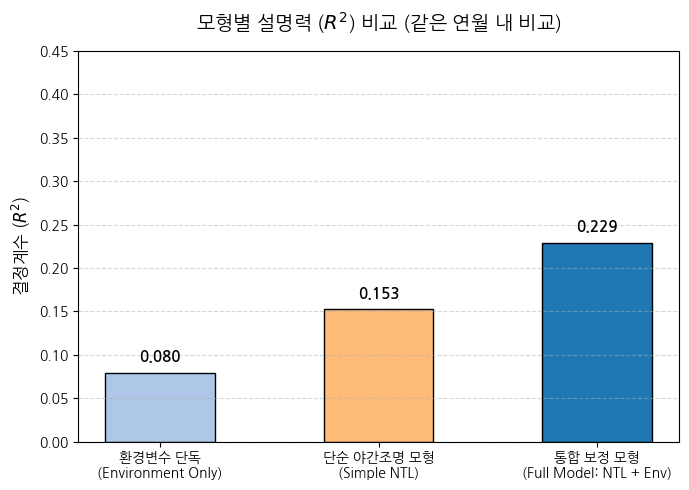

In [28]:
import matplotlib.pyplot as plt
import pandas as pd

# R² 값 정리 (10번 및 11번 결과 기준)
r2_data = {
    'Model': [
        '환경변수 단독\n(Environment Only)',
        '단순 야간조명 모형\n(Simple NTL)',
        '통합 보정 모형\n(Full Model: NTL + Env)'
    ],
    'R2': [res['r2_env'], res['r2_simple'], res['r2_full']]
}
r2_df = pd.DataFrame(r2_data)

# 시각화 설정
plt.figure(figsize=(7, 5))
colors = ['#aec7e8', '#ffbb78', '#1f77b4']
bars = plt.bar(r2_df['Model'], r2_df['R2'], color=colors, edgecolor='black', width=0.5)

# 바 위에 값 표시
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, height + 0.01, f'{height:.3f}',
             ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.ylim(0, 0.45)
plt.ylabel('결정계수 ($R^2$)', fontsize=12)
plt.title('모형별 설명력 ($R^2$) 비교 (같은 연월 내 비교)', fontsize=14, pad=15)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [33]:
# 12. 세부목적 3: 최소 유효 관측 수 기준 민감도 평가
print('민감도 분석: 최소 유효 관측 수 기준')
print('적용 기준:', THRESHOLDS)

민감도 분석: 최소 유효 관측 수 기준
적용 기준: [1, 3, 5, 7, 10]


In [34]:
# 13. 세부목적 3: 최소 유효 관측 수 기준 민감도 분석

sens_rows = []

for t_ in THRESHOLDS:

    # 전체 기간에서 최소 유효 관측 수 기준 적용
    d = df[df['n_valid'] >= t_].copy()

    if len(d) < 300 or d['ym'].nunique() < 3:
        print(t_, ': 표본 부족으로 제외')
        continue

    # 환경변수 보정 회귀분석
    r = fit_set(d)
    r['min_valid'] = t_

    sens_rows.append(r)

sens = pd.DataFrame(sens_rows)

if len(sens):

    sens = sens.sort_values('min_valid')

    print('최소 유효 관측 수 기준별 민감도 분석 결과')

    print(sens[
        ['min_valid', 'n', 'n_pixel', 'n_ym',
         'beta_simple', 'beta_adj',
         'ci_lo', 'ci_hi', 'p_adj',
         'r2_full', 'delta_r2']
    ].round(4).to_string(index=False))

    # 기준별 회귀계수 방향 유지 여부
    sign_kept = (
        np.sign(sens['beta_adj']) ==
        np.sign(sens['beta_adj'].iloc[0])
    ).all()

    print('\\n회귀계수 방향 유지 여부:', sign_kept)

    print('회귀계수 최소값:', sens['beta_adj'].min())
    print('회귀계수 최대값:', sens['beta_adj'].max())

else:
    print('민감도 분석을 수행할 표본이 부족합니다.')

최소 유효 관측 수 기준별 민감도 분석 결과
 min_valid     n  n_pixel  n_ym  beta_simple  beta_adj  ci_lo  ci_hi  p_adj  r2_full  delta_r2
         1 22091      471    48        0.492     0.577  0.512  0.641  0.000    0.211     0.131
         3 20889      471    48        0.492     0.583  0.518  0.647  0.000    0.229     0.149
         5 17633      471    47        0.477     0.594  0.528  0.660  0.000    0.254     0.176
         7 13280      471    47        0.447     0.593  0.525  0.661  0.000    0.281     0.194
        10  8130      470    46        0.461     0.637  0.563  0.711  0.000    0.336     0.235
\n회귀계수 방향 유지 여부: True
회귀계수 최소값: 0.5767249364432614
회귀계수 최대값: 0.6371656920300858


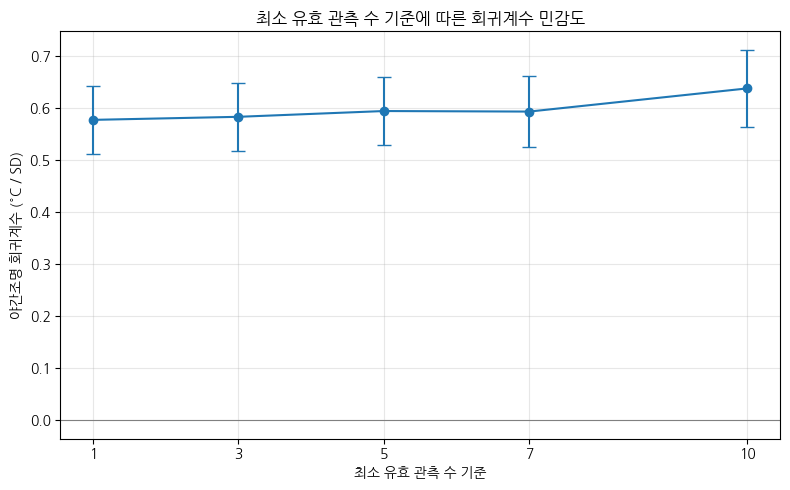

In [35]:
# 14. 최소 유효 관측 수 기준별 NTL 회귀계수 및 95% CI

if len(sens):

    plt.figure(figsize=(8, 5))

    plt.errorbar(
        sens['min_valid'],
        sens['beta_adj'],
        yerr=[
            sens['beta_adj'] - sens['ci_lo'],
            sens['ci_hi'] - sens['beta_adj']
        ],
        fmt='o-',
        capsize=5
    )

    plt.axhline(0, color='gray', lw=0.8)

    plt.xlabel('최소 유효 관측 수 기준')
    plt.ylabel('야간조명 회귀계수 (°C / SD)')
    plt.title('최소 유효 관측 수 기준에 따른 회귀계수 민감도')

    plt.xticks(THRESHOLDS)
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

In [36]:
# 15. 결과 저장

# 세부목적 1: 전체 격자 월별 상관관계
monthly.to_csv(
    f'{BASE_DIR}/result_monthly_corr.csv'
)

# 세부목적 1: 토지이용 유형별 결과
if 'landuse_monthly' in globals():
    landuse_monthly.to_csv(
        f'{BASE_DIR}/result_landuse_monthly.csv',
        index=False
    )

if 'landuse_results' in globals():
    landuse_results.to_csv(
        f'{BASE_DIR}/result_landuse_regression.csv',
        index=False
    )

# 세부목적 3: 최소 유효 관측 수 기준 민감도 분석
if 'sens' in globals() and len(sens) > 0:
    sens.to_csv(
        f'{BASE_DIR}/result_sensitivity.csv',
        index=False
    )

print('결과 저장 완료:', BASE_DIR)

결과 저장 완료: /content/drive/MyDrive/busan_ntl_lst
